# Week 5: Language detection, translation, England filter and reranking

Runs on the project pipeline in `src/`. The week 5 experiment results are read from `results/`.

In [1]:
import sys, pathlib
import pandas as pd
ROOT = pathlib.Path.cwd().parent if pathlib.Path.cwd().name == 'notebooks' else pathlib.Path.cwd()
sys.path.insert(0, str(ROOT / 'src'))
pd.set_option('display.max_colwidth', 90)

## 1. Language identification

`src/language.py` uses lingua restricted to the five project languages. Arabic and Urdu share a script, so restricting the set matters most for those two.

In [2]:
from language import detect
for q in ['How do I register with a GP surgery?', 'Jak zarejestrować się u lekarza rodzinnego?',
          'Cum mă înregistrez la un medic de familie?', 'كيف أسجل لدى طبيب عام؟', 'میں جی پی کے پاس رجسٹریشن کیسے کرواؤں؟']:
    print(detect(q), '|', q)
pd.read_csv(ROOT / 'results/week5_language_id.csv')

en | How do I register with a GP surgery?
pl | Jak zarejestrować się u lekarza rodzinnego?
ro | Cum mă înregistrez la un medic de familie?
ar | كيف أسجل لدى طبيب عام؟
ur | میں جی پی کے پاس رجسٹریشن کیسے کرواؤں؟


,lang,accuracy
0,ar,1.0
1,en,1.0
2,pl,1.0
3,ro,1.0
4,ur,1.0


## 2. Translation to English (NLLB-200)

`src/translate.py` splits text into sentences first: NLLB is trained on single sentences and silently dropped the second sentence of two-sentence questions before this fix.

In [3]:
tr = pd.read_csv(ROOT / 'eval/translations_nllb.csv')
tr[tr.qid.isin(['M01', 'H06'])][['qid', 'lang', 'question', 'nllb_english']]

,qid,lang,question,nllb_english
15,H06,ar,أنا على وشك أن أفقد منزلي، هل يمكن للمجلس المحلي مساعدتي؟,I'm about to lose my house. Can the local council help me?
20,M01,ar,كيف أسجل لدى طبيب عام؟,How do I register with a general practitioner?
45,H06,pl,Zaraz stracę dom. Czy lokalny urząd może mi pomóc?,I'm about to lose my house. Can the local office help me?
50,M01,pl,Jak zarejestrować się u lekarza rodzinnego?,How do I register with a family doctor?
75,H06,ro,Sunt pe punctul de a-mi pierde locuința. Mă poate ajuta consiliul local?,I'm about to lose my home. Can the local council help me?
80,M01,ro,Cum mă înregistrez la un medic de familie?,How do I register with a family doctor?
105,H06,ur,میرا گھر چھننے والا ہے، کیا کونسل میری مدد کر سکتی ہے؟,"My house is on the verge of collapse, can the council help me?"
110,M01,ur,میں جی پی کے پاس رجسٹریشن کیسے کرواؤں؟,How do I register with the GP?


Manual review of all 120 translations (by the author, not a native speaker): **11 change the meaning** and **8 lose a key term**. Most errors are in housing vocabulary (deposit, evict).

In [4]:
review = pd.read_csv(ROOT / 'eval/translation_review.csv')
print(review.issue.value_counts().to_string())
review[review.issue == 'meaning changed'][['qid', 'lang', 'nllb_english', 'note']]

issue
meaning changed    11
key term lost       8


,qid,lang,nllb_english,note
8,H01,ar,Can the owner fire me without giving a reason?,"""evict"" -> ""fire"" (يطرد means both)"
9,H03,ar,The owner took insurance money from me. Does that insurance have to be protected?,"""deposit"" -> ""insurance money"""
10,H03,pl,The landlord took my bail. Does it have to be secured?,"""deposit"" (kaucja) -> ""bail"""
11,H03,ro,The landlord got me a warranty. Does this have to be protected?,"""deposit"" (garanție) -> ""warranty"""
12,H06,ur,"My house is on the verge of collapse, can the council help me?","""about to lose my home"" -> ""house on the verge of collapse"""
13,H07,pl,Does the tenant have to keep the rented apartment in good technical condition?,obligation moved from landlord to tenant
14,H08,ur,How much should I inform the landlord before I return home?,roles reversed: I inform the landlord before I return home
15,H10,ar,What can I do if the local council or the housing association wants me fired?,"""evict"" -> ""fired"""
16,S02,pl,When do you have to apply for a high school job?,"""school place"" -> ""high school job"""
17,S08,pl,How old can my child go to school?,"""leave school"" -> ""go to school"""


## 3. England filter

`src/chunk.py` tags each section by the UK nation named in its heading. Six chunks are for Scotland, Wales or Northern Ireland; search keeps England / UK-wide chunks only.

In [5]:
chunks = pd.read_csv(ROOT / 'data/processed/chunks.csv')
print(chunks.nation.value_counts().to_string())
chunks[chunks.nation != 'england'][['title', 'heading', 'nation']]

nation
england                            429
scotland                             2
scotland;wales;northern_ireland      1
wales                                1
northern_ireland                     1
scotland;northern_ireland            1


,title,heading,nation
52,School uniform,"If you live in Scotland, Wales or Northern Ireland",scotland;wales;northern_ireland
69,School leaving age,Scotland,scotland
70,School leaving age,Wales,wales
71,School leaving age,Northern Ireland,northern_ireland
183,Tenancy deposit protection,If you’re in Scotland or Northern Ireland,scotland;northern_ireland
281,Universal Credit,If you live in Scotland,scotland


## 4. Full search pipeline

`src/pipeline.py`: detect language > translate > search with both the original and the English question > fuse the two lists (reciprocal rank fusion) > keep England chunks > rerank the top 20 with bge-reranker-v2-m3 > top 3 passages.

In [6]:
from pipeline import SearchPipeline
pipe = SearchPipeline()

def show(q):
    r = pipe.search(q)
    print(f"Q [{r['lang']}] {q}\n   NLLB English: {r['english_query']}")
    for x in r['results']:
        print(f"   - {x['title']} > {x['heading'][:60]}  [{x['nation']}]\n     {x['text'][:140]}...")
    print()

show('At what age can my child leave school?')             # week 4 returned the Scotland rule first
show('هل يمكن للمالك أن يطردني دون إبداء سبب؟')              # Arabic: NLLB says 'fire me', search still finds eviction rules
show('میرا گھر چھننے والا ہے، کیا کونسل میری مدد کر سکتی ہے؟')  # Urdu: NLLB says 'collapse', search still finds homelessness help

W1102 11:23:03.809000 67946 torch/distributed/elastic/multiprocessing/redirects.py:35] NOTE: Redirects are currently not supported in MacOs.


Q [en] At what age can my child leave school?
   NLLB English: At what age can my child leave school?
   - School leaving age > School leaving age / England  [england]
     Your school leaving age depends on where you live. You can leave school on the last Friday in June if you’ll be 16 by the end of the summer ...
   - School admissions > If your child starts in the September after they turn 5 / Co  [england]
     Your child will go into year 1 . Contact the local council or school if you want your child to start in reception instead. They do not have ...
   - Complain about a school > Who can complain to the SEND tribunal  [england]
     You can complain to the tribunal if you’re: someone with parental responsibility for a young person, or their foster parent or carer a young...



Q [ar] هل يمكن للمالك أن يطردني دون إبداء سبب؟
   NLLB English: Can the owner fire me without giving a reason?
   - Renters’ Rights Act overview for tenants > If your landlord wants to end your tenancy  [england]
     If your landlord wants to end your assured periodic tenancy after 1 May 2026 they will need to give you a reason for evicting you when they ...
   - Private renting for tenants: evictions in England > The judge’s decision  [england]
     The judge could: make a ‘possession order’ - the judge will make a legal decision on when you may be required to leave the property make a ‘...
   - Private renting > If your landlord takes you to court to evict you  [england]
     If you owe at least 3 months’ worth of rent (meaning you’re in more than 3 months’ arrears), the court may ignore them. They can only do thi...



Q [ur] میرا گھر چھننے والا ہے، کیا کونسل میری مدد کر سکتی ہے؟
   NLLB English: My house is on the verge of collapse, can the council help me?
   - Help from your council if you’re homeless or at risk of homelessness > Help from your council if you’re homeless or at risk of home  [england]
     Get help and advice from the local council if you’re homeless or about to lose your home. There’s a different way to get help in Scotland an...
   - Council housing > Leaving your home  [england]
     You may have to leave your home if major works are needed on the building. Your council must find you somewhere to live while work is carrie...
   - Help from your council if you’re homeless or at risk of homelessness > If you’re applying for housing support from a council in Eng  [england]
     You do not need to have a local connection if you are: a current or former member of the UK armed forces a bereaved spouse or civil partner ...



## 5. Experiment: six set-ups on the 150-query test set

Same metrics as week 4. **ans@3** = a top-3 chunk contains the verbatim answer phrase. Regenerate with `python eval/evaluate_week5.py`.

In [7]:
res = pd.read_csv(ROOT / 'results/week5_by_lang.csv')
res[res.lang == 'ALL'].drop(columns='lang').set_index('system')

,hit@1,hit@3,mrr@10,ans@3
system,,,,
A direct,0.813,0.960,0.892,0.667
B direct+filter,0.787,0.953,0.875,0.680
C translated+filter,0.833,0.973,0.907,0.747
D fusion+filter,0.833,0.980,0.906,0.713
E direct+filter+rerank,0.920,0.993,0.956,0.867
F fusion+filter+rerank,0.940,1.000,0.969,0.893


In [8]:
per_q = pd.read_csv(ROOT / 'results/week5_per_query.csv')
langs = ['en', 'pl', 'ro', 'ar', 'ur']
per_q.pivot_table(index='system', columns='lang', values='ans@3').round(2)[langs]

lang,en,pl,ro,ar,ur
system,,,,,
A direct,0.77,0.70,0.67,0.73,0.47
B direct+filter,0.80,0.70,0.67,0.77,0.47
C translated+filter,0.80,0.70,0.70,0.80,0.73
D fusion+filter,0.80,0.73,0.63,0.80,0.60
E direct+filter+rerank,0.90,0.87,0.80,0.90,0.87
F fusion+filter+rerank,0.90,0.90,0.87,0.90,0.90


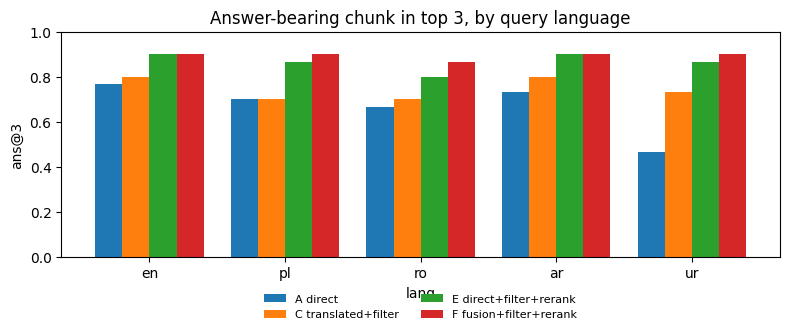

In [9]:
import matplotlib.pyplot as plt
show_sys = ['A direct', 'C translated+filter', 'E direct+filter+rerank', 'F fusion+filter+rerank']
t = per_q[per_q.system.isin(show_sys)].pivot_table(index='lang', columns='system', values='ans@3').loc[langs, show_sys]
ax = t.plot.bar(figsize=(8, 3.5), rot=0, width=0.8)
ax.set_ylabel('ans@3'); ax.set_ylim(0, 1); ax.set_title('Answer-bearing chunk in top 3, by query language')
ax.legend(frameon=False, ncol=2, fontsize=8, loc='upper center', bbox_to_anchor=(0.5, -0.12))
plt.tight_layout(); plt.show()

In [10]:
print('queries whose top chunk is for another UK nation:')
per_q[per_q.top1_nation != 'england'].groupby('system').size()

queries whose top chunk is for another UK nation:


system
A direct    4
dtype: int64

## Findings

* Language ID was correct for all 150 test questions (clean, full sentences; real users may mix languages).
* Translating first helps Urdu most (ans@3 0.47 to 0.73) even though 19 of 120 translations have errors.
* Reranking gives the largest single gain (0.68 to 0.87 with the filter).
* The chosen set-up, **F fusion+filter+rerank**, reaches hit@3 1.00 and ans@3 0.89, with all five languages at 0.87 or above.
* No top result comes from another UK nation's rules once the filter is on.

## Next (week 6)
Give the top passages to an LLM, answer only from them with numbered citations, refuse when nothing relevant is found, and return the answer in the user's language.